# Pipeline base de clasificación con PyTorch
**Proyecto integrador · Data Science III · Módulo 1**  
**Preparado para:** Hans · **Dataset:** Iris

Este notebook implementa un experimento completo con un MLP `4 → 16 → 16 → 3`, Adam y 50 épocas. Está alineado con la Parte 4 del notebook de clase y las diapositivas 30–39 del módulo.

**Uso:** reiniciar el kernel y ejecutar todas las celdas en orden. No depende de ejecutar previamente el notebook de clase. Los archivos de resultados y el README se regeneran con esta ejecución.

**Objetivo:** verificar un pipeline funcional y explicar cómo aprende; no prometer un accuracy particular ni demostrar desempeño productivo con solo 30 ejemplos de validación.

## 1. Fundamentos que aplicaremos
| Concepto | Aplicación |
|---|---|
| Perceptrón | Cada capa lineal calcula una transformación afín: pesos y sesgos. |
| No linealidad y XOR | Varias transformaciones afines sin activación se reducen a una transformación afín. ReLU permite aprender relaciones no lineales. XOR ilustra esta necesidad; no es nuestro dataset de entrenamiento. |
| ReLU | Activa las capas ocultas. Su derivada vale 1 en la zona positiva y 0 en la negativa; no garantiza por sí sola que desaparezcan los problemas de gradientes. |
| Backpropagation | Aplica la regla de la cadena para obtener los gradientes de la pérdida respecto de los parámetros. |
| Autograd | PyTorch registra las operaciones y calcula esos gradientes con `backward()`. |
| Adam | Utiliza estimaciones de primer y segundo momento de los gradientes para actualizar parámetros. |
| Generalización | Evaluamos ejemplos que no se utilizan para actualizar pesos. |

Una **época** recorre todo el conjunto de entrenamiento. Cada **lote** realiza un forward, cálculo de pérdida, backward y actualización. Validar permite detectar problemas; no elimina automáticamente el sobreajuste.

## 2. Configuración y reproducibilidad
Se fija una única configuración. El material original contiene código con `lr=0.01` y una salida guardada con `0.05`; aquí el README se genera desde el mismo diccionario utilizado para entrenar.

Las semillas facilitan repetir la ejecución dentro del mismo entorno. No garantizan resultados idénticos entre diferentes versiones, CPU, CUDA y MPS. La instalación de PyTorch debe corresponder al equipo utilizado.

In [1]:
from pathlib import Path
import csv
import json
import platform
import random
import copy
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
import sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

CONFIG = dict(seed=42, validation_size=0.2, input_dim=4,
              hidden_dim=16, output_dim=3, batch_size=16,
              learning_rate=0.01, epochs=50)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG['seed'])
# Un hilo es suficiente para este dataset pequeño y evita sobrecostos en CPU.
torch.set_num_threads(1)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
# Funciona al abrir desde la raíz del proyecto o desde notebooks/.
cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == 'notebooks' else cwd
REPORTS = ROOT / 'reports'
REPORTS.mkdir(parents=True, exist_ok=True)
ENV = {'python': platform.python_version(), 'torch': str(torch.__version__),
       'numpy': np.__version__, 'scikit-learn': sklearn.__version__,
       'matplotlib': importlib.metadata.version('matplotlib'),
       'device': str(device)}
print(json.dumps(ENV, indent=2))
print('Configuración:', CONFIG)

{
  "python": "3.12.14",
  "torch": "2.15.0+cpu",
  "numpy": "2.3.5",
  "scikit-learn": "1.8.0",
  "matplotlib": "3.10.8",
  "device": "cpu"
}
Configuración: {'seed': 42, 'validation_size': 0.2, 'input_dim': 4, 'hidden_dim': 16, 'output_dim': 3, 'batch_size': 16, 'learning_rate': 0.01, 'epochs': 50}


## 3. Dataset y exploración mínima
Iris contiene mediciones del sépalo y del pétalo de tres especies. Inspeccionamos dimensiones, balance, valores ausentes y rangos antes de entrenar. La carga se realiza desde scikit-learn, sin descargar archivos externos.

In [2]:
iris = load_iris()
X, y = iris.data, iris.target
print('X:', X.shape, '| y:', y.shape)
print('Clases:', dict(zip(iris.target_names, np.bincount(y).tolist())))
print('Valores no finitos:', (~np.isfinite(X)).sum())
for name, lo, hi in zip(iris.feature_names, X.min(axis=0), X.max(axis=0)):
    print(f'{name}: mínimo={lo:.2f}, máximo={hi:.2f}')
assert X.shape == (150, 4) and np.isfinite(X).all()
assert set(np.unique(y)) == {0, 1, 2}

X: (150, 4) | y: (150,)
Clases: {np.str_('setosa'): 50, np.str_('versicolor'): 50, np.str_('virginica'): 50}
Valores no finitos: 0
sepal length (cm): mínimo=4.30, máximo=7.90
sepal width (cm): mínimo=2.00, máximo=4.40
petal length (cm): mínimo=1.00, máximo=6.90
petal width (cm): mínimo=0.10, máximo=2.50


## 4. Separación, escalado y tensores
Separación estratificada: 120 observaciones para entrenamiento y 30 para validación. Ajustamos el escalador **solo** con entrenamiento; después transformamos validación con las mismas medias y desviaciones. Así evitamos fuga de información.

Los datos de entrada son `float32`. Las etiquetas son índices enteros (`long`), porque `CrossEntropyLoss` espera una clase por ejemplo. Las entradas no requieren gradientes: los parámetros de `nn.Module` ya los habilitan automáticamente.

In [3]:
indices_train, indices_val = train_test_split(
    np.arange(len(y)), test_size=CONFIG['validation_size'],
    random_state=CONFIG['seed'], stratify=y)
assert set(indices_train).isdisjoint(indices_val)
scaler = StandardScaler()
X_train = scaler.fit_transform(X[indices_train])
X_val = scaler.transform(X[indices_val])
y_train, y_val = y[indices_train], y[indices_val]
print('Train:', X_train.shape, '| Validación:', X_val.shape)
print('Primera fila original:', X[indices_train][0])
print('Primera fila escalada:', X_train[0].round(3))
print('Medias de entrenamiento:', X_train.mean(axis=0).round(6))

train_ds = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                         torch.tensor(y_train, dtype=torch.long))
val_ds = TensorDataset(torch.tensor(X_val, dtype=torch.float32),
                       torch.tensor(y_val, dtype=torch.long))

Train: (120, 4) | Validación: (30, 4)
Primera fila original: [4.4 2.9 1.4 0.2]
Primera fila escalada: [-1.722 -0.332 -1.346 -1.323]
Medias de entrenamiento: [-0. -0.  0.  0.]


## 5. Arquitectura y dimensiones
Dos capas ocultas de 16 neuronas con ReLU. La salida tiene tres **logits** (puntajes sin normalizar), uno por clase. No añadimos Softmax antes de `CrossEntropyLoss`, que incorpora internamente la operación necesaria. Para decidir la clase basta con `argmax`; para mostrar probabilidades se puede aplicar Softmax después.

In [4]:
class BaseClassifier(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=16, output_dim=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, output_dim))

    def forward(self, x):
        return self.net(x)

set_seed(CONFIG['seed'])
model = BaseClassifier(CONFIG['input_dim'], CONFIG['hidden_dim'],
                       CONFIG['output_dim']).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'])
with torch.no_grad():
    output = model(train_ds.tensors[0][:5].to(device))
assert output.shape == (5, 3)
print(model)
print('Prueba de dimensiones:', output.shape)
print('Parámetros entrenables:', sum(p.numel() for p in model.parameters()))

BaseClassifier(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)
Prueba de dimensiones: torch.Size([5, 3])
Parámetros entrenables: 403


## 6. Funciones de entrenamiento y evaluación
`zero_grad()` limpia gradientes acumulados; `backward()` los calcula; `step()` actualiza los pesos. Omitir `step()` impide aprender y omitir `zero_grad()` acumula gradientes entre lotes involuntariamente.

La pérdida promedio se pondera por el número de observaciones de cada lote, incluido el último lote incompleto. Accuracy = aciertos / total.

`model.eval()` cambia el comportamiento de capas que dependen del modo, mientras `torch.no_grad()` desactiva el registro de gradientes. Son funciones diferentes. Este MLP no incluye Dropout ni BatchNorm, pero mantenemos la estructura correcta.

In [5]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(inputs)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss):
            raise RuntimeError('Pérdida no finita: revisar datos y configuración.')
        loss.backward()
        optimizer.step()
        total += labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        loss_sum += loss.item() * labels.size(0)
    return loss_sum / total, correct / total


def evaluate(model, dataloader, criterion, device):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            logits = model(inputs)
            loss = criterion(logits, labels)
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total

## 7. Comprobación de autograd y actualización de pesos
Usamos una **copia** del modelo para verificar gradientes finitos y al menos un cambio en los parámetros. Esta prueba no modifica el modelo del experimento ni exige que todas las neuronas tengan gradiente distinto de cero.

In [6]:
probe = copy.deepcopy(model)
probe_optimizer = optim.Adam(probe.parameters(), lr=CONFIG['learning_rate'])
probe_x, probe_y = (t[:16].to(device) for t in train_ds.tensors)
before = [p.detach().clone() for p in probe.parameters()]
probe_optimizer.zero_grad()
probe_loss = criterion(probe(probe_x), probe_y)
probe_loss.backward()
grads = [p.grad for p in probe.parameters()]
assert all(g is not None and torch.isfinite(g).all() for g in grads)
assert any(torch.count_nonzero(g).item() > 0 for g in grads)
probe_optimizer.step()
assert any(not torch.equal(a, b) for a, b in zip(before, probe.parameters()))
print('OK: backward calculó gradientes y Adam actualizó los parámetros.')
del probe, probe_optimizer

OK: backward calculó gradientes y Adam actualizó los parámetros.


## 8. Experimento de 50 épocas
Se reinicializan modelo, optimizador y generador de lotes para evitar entrenamientos acumulados al repetir esta celda. Se registra también la pérdida antes de entrenar.

La métrica de entrenamiento se acumula mientras los pesos cambian dentro de la época; validación se mide con el modelo al terminar la época. Por ello no son mediciones exactamente simultáneas. El conjunto de validación no constituye un test final independiente para comparar muchos modelos.

In [7]:
set_seed(CONFIG['seed'])
generator = torch.Generator().manual_seed(CONFIG['seed'])
train_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'],
                          shuffle=True, generator=generator, num_workers=0)
train_eval_loader = DataLoader(train_ds, batch_size=CONFIG['batch_size'], shuffle=False)
val_loader = DataLoader(val_ds, batch_size=CONFIG['batch_size'], shuffle=False)
model = BaseClassifier(CONFIG['input_dim'], CONFIG['hidden_dim'],
                       CONFIG['output_dim']).to(device)
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'])
initial_train = evaluate(model, train_eval_loader, criterion, device)
initial_val = evaluate(model, val_loader, criterion, device)
history = []
for epoch in range(1, CONFIG['epochs'] + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    history.append(dict(epoch=epoch, train_loss=train_loss, train_accuracy=train_acc,
                        val_loss=val_loss, val_accuracy=val_acc))
    if epoch == 1 or epoch % 10 == 0:
        print(f'{epoch:02d}/{CONFIG["epochs"]} | train loss={train_loss:.4f} '
              f'acc={train_acc:.2%} | val loss={val_loss:.4f} acc={val_acc:.2%}')
assert len(history) == CONFIG['epochs']
assert all(np.isfinite(list(row.values())).all() for row in history)
assert all(0 <= row[k] <= 1 for row in history for k in ['train_accuracy', 'val_accuracy'])
# La evaluación no debe cambiar parámetros ni buffers del modelo.
state_before_eval = {k: v.clone() for k, v in model.state_dict().items()}
final_eval = evaluate(model, val_loader, criterion, device)
assert all(torch.equal(v, model.state_dict()[k]) for k, v in state_before_eval.items())
print('OK: 50 épocas completas, métricas finitas y evaluación sin modificar pesos.')

01/50 | train loss=0.9989 acc=66.67% | val loss=0.8571 acc=76.67%
10/50 | train loss=0.0883 acc=95.00% | val loss=0.1152 acc=93.33%
20/50 | train loss=0.0495 acc=98.33% | val loss=0.0963 acc=96.67%
30/50 | train loss=0.0455 acc=98.33% | val loss=0.1007 acc=96.67%
40/50 | train loss=0.0296 acc=98.33% | val loss=0.0960 acc=96.67%
50/50 | train loss=0.0239 acc=99.17% | val loss=0.1122 acc=96.67%
OK: 50 épocas completas, métricas finitas y evaluación sin modificar pesos.


## 9. Curvas y matriz de confusión
La pérdida considera la confianza asignada a las clases; el accuracy solo distingue aciertos y errores. Pueden moverse de forma diferente. En 30 muestras, una predicción cambia el accuracy en 3,33 puntos porcentuales.

La matriz de confusión es un complemento para identificar qué especies confunde el modelo final. No sustituye la pérdida ni la validación independiente exigidas.

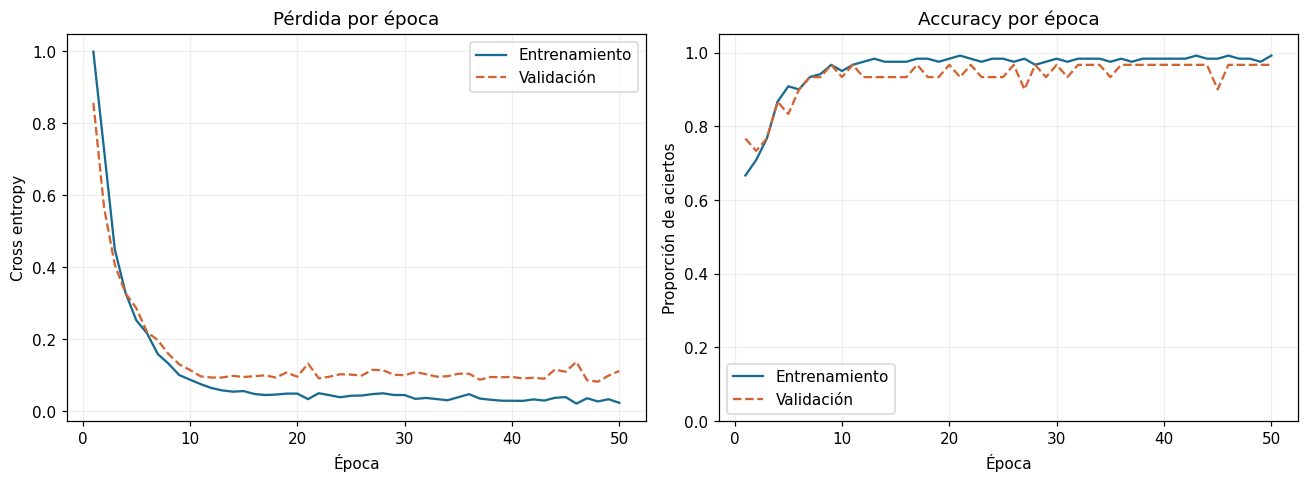

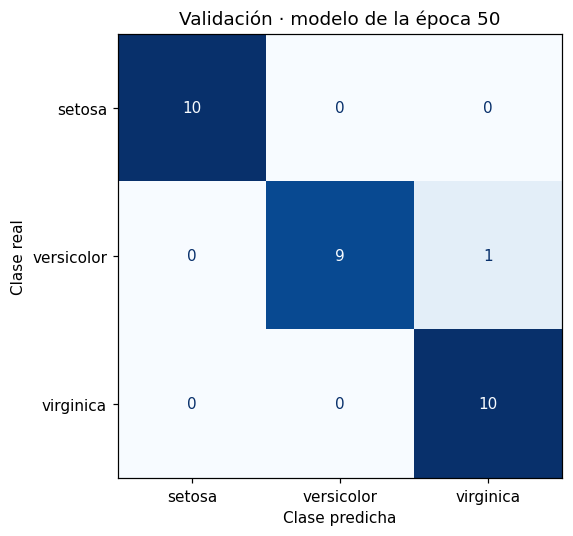

In [8]:
epochs = [r['epoch'] for r in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, train_key, val_key, title, ylabel in [
    (axes[0], 'train_loss', 'val_loss', 'Pérdida por época', 'Cross entropy'),
    (axes[1], 'train_accuracy', 'val_accuracy', 'Accuracy por época', 'Proporción de aciertos')]:
    ax.plot(epochs, [r[train_key] for r in history], label='Entrenamiento', color='#176B91')
    ax.plot(epochs, [r[val_key] for r in history], label='Validación', color='#D36332', linestyle='--')
    ax.set(title=title, xlabel='Época', ylabel=ylabel)
    ax.grid(alpha=0.2)
    ax.legend()
axes[1].set_ylim(0, 1.05)
fig.tight_layout()
fig.savefig(REPORTS / 'curvas_entrenamiento.png', dpi=160, bbox_inches='tight')
plt.show()

model.eval()
with torch.no_grad():
    predictions = model(val_ds.tensors[0].to(device)).argmax(dim=1).cpu().numpy()
assert np.isclose((predictions == y_val).mean(), final_eval[1])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_val, predictions, labels=[0, 1, 2]),
                       display_labels=iris.target_names).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Validación · modelo de la época 50')
ax.set_xlabel('Clase predicha')
ax.set_ylabel('Clase real')
fig.tight_layout()
fig.savefig(REPORTS / 'matriz_confusion.png', dpi=160, bbox_inches='tight')
plt.show()

## 10. Resultados y conclusiones basadas en evidencia
Se compara la pérdida inicial (antes de entrenar), la final y la mínima de validación. La mínima identifica una época observada; **no se restaura ese modelo** y el accuracy final corresponde a la época 50.

La redacción automática siguiente describe cifras y variaciones, sin afirmar que las pérdidas bajaron de forma monótona o que se descartó el sobreajuste. Si la validación empeora sostenidamente, conviene comparar un learning rate menor o considerar parada temprana en una siguiente versión. Esas modificaciones deben registrarse como experimentos separados.

In [9]:
first, last = history[0], history[-1]
best = min(history, key=lambda r: r['val_loss'])
increases = sum(b['val_loss'] > a['val_loss'] for a, b in zip(history, history[1:]))
interpretation = (
    f"La pérdida antes de entrenar fue {initial_train[0]:.4f} en entrenamiento y "
    f"{initial_val[0]:.4f} en validación. En la época 50 fue "
    f"{last['train_loss']:.4f} y {last['val_loss']:.4f}, respectivamente. "
    f"La pérdida mínima observada de validación fue {best['val_loss']:.4f} "
    f"en la época {best['epoch']}. Hubo {increases} incrementos entre épocas "
    f"consecutivas de validación (de 49 comparaciones). "
    f"El accuracy final fue {last['val_accuracy']:.2%}, equivalente a "
    f"{int((predictions == y_val).sum())}/30 aciertos. "
    "Estas métricas corresponden a una partición pequeña y no prueban ausencia de sobreajuste."
)
print(interpretation)
with (REPORTS / 'metricas.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=list(first))
    writer.writeheader()
    writer.writerows(history)
summary = {'configuration': CONFIG, 'environment': ENV,
           'initial_train_loss': initial_train[0], 'initial_val_loss': initial_val[0],
           'final': last, 'minimum_validation_loss_epoch': best,
           'interpretation': interpretation,
           'train_indices': indices_train.tolist(), 'validation_indices': indices_val.tolist()}
(REPORTS / 'resumen.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')

readme = f"""# Pipeline base de clasificación con PyTorch
Proyecto integrador · Data Science III · Módulo 1. Preparado para Hans.

## Objetivo y datos
Clasificar las tres especies de Iris usando cuatro mediciones, con un MLP 4 → 16 → 16 → 3 y ReLU.
120 ejemplos de entrenamiento y 30 de validación; división estratificada y StandardScaler ajustado solo con entrenamiento.

## Instalación y ejecución
Referencia de ejecución: Python {ENV['python']}, PyTorch {ENV['torch']}, dispositivo {device}.

1. Descomprimir el proyecto y abrir una terminal en su raíz.
2. Crear entorno: `python -m venv .venv`.
3. Activar en Windows PowerShell: `.venv\\Scripts\\Activate.ps1`; en macOS/Linux: `source .venv/bin/activate`.
4. Instalar: `python -m pip install -r requirements.txt`.
5. Abrir `notebooks/01_pipeline_base.ipynb` en VS Code con las extensiones Python/Jupyter y seleccionar ese entorno.
6. Reiniciar el kernel y ejecutar todas las celdas. Se regeneran README y reports/.

Para Colab, subir el notebook y ejecutar con sus librerías disponibles; revisar las versiones impresas.
Para usar GPU, instalar previamente la variante de PyTorch compatible desde https://pytorch.org/get-started/locally/.
La detección CUDA/MPS/CPU es automática; este proyecto fue verificado en {device}, no en todos los dispositivos.
Las semillas no garantizan identidad numérica entre hardware y versiones.

## Configuración
- Semilla: {CONFIG['seed']}
- Adam, learning_rate: {CONFIG['learning_rate']}
- Épocas: {CONFIG['epochs']}; batch_size: {CONFIG['batch_size']}
- Pérdida: CrossEntropyLoss sobre logits, sin Softmax previo.
- Datos: float32; etiquetas: long.

## Resultados reales de esta ejecución
{interpretation}

![Curvas](reports/curvas_entrenamiento.png)
![Matriz de confusión](reports/matriz_confusion.png)

## Validaciones incorporadas
Dimensiones, conjuntos separados, gradientes finitos, actualización de pesos, métricas finitas y evaluación sin cambios en el modelo.
Las métricas de entrenamiento se acumulan durante las actualizaciones; validación se calcula al final de cada época.
No se utiliza un conjunto de test independiente ni se guarda/restaura un modelo de la mejor época.

## Estructura
- data/README.md: descripción del origen de los datos.
- notebooks/01_pipeline_base.ipynb: desarrollo autónomo y comentado.
- reports/: métricas, resumen con configuración e índices y figuras.
- requirements.txt: versiones del entorno verificado.
- GUIA_ENTREGA.md: instrucciones de versionado y entrega.

## Fuentes
Material adjunto: presentación Módulo 1 Data Science III, diapositivas 30–39, y notebook de clase, Parte 4.
- https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html
- https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
- https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
- https://scikit-learn.org/stable/common_pitfalls.html

## Alcance
Pre-entrega técnica: pipeline funcional y comprensible. Las 30 muestras de validación no permiten asegurar rendimiento en producción.
Un checkpoint de pesos es opcional y no forma parte de esta versión.
"""
(ROOT / 'README.md').write_text(readme, encoding='utf-8')
packages = ['torch', 'numpy', 'scikit-learn', 'matplotlib', 'ipykernel', 'nbformat', 'nbclient']
requirements = '\n'.join(f"{p}=={importlib.metadata.version(p).split('+')[0]}" for p in packages)
(ROOT / 'requirements.txt').write_text(requirements + '\n', encoding='utf-8')
print('Archivos generados en:', ROOT)

La pérdida antes de entrenar fue 1.0924 en entrenamiento y 1.0948 en validación. En la época 50 fue 0.0239 y 0.1122, respectivamente. La pérdida mínima observada de validación fue 0.0825 en la época 48. Hubo 19 incrementos entre épocas consecutivas de validación (de 49 comparaciones). El accuracy final fue 96.67%, equivalente a 29/30 aciertos. Estas métricas corresponden a una partición pequeña y no prueban ausencia de sobreajuste.
Archivos generados en: /workspace/scratch/84243379e349/pipeline_base_pytorch


## 11. Lista de revisión antes de entregar
- [ ] Reinicié el kernel y ejecuté todas las celdas sin errores.
- [ ] README, curvas y métricas corresponden a la misma ejecución.
- [ ] Puedo explicar ReLU, logits, loss, backward, zero_grad y step.
- [ ] Registré los cambios en Git con mensajes descriptivos.
- [ ] Subí el proyecto a mi repositorio y comprobé que el evaluador puede acceder.

**Referencias del curso:** presentación Módulo 1 (diapositivas 7–25 y 30–39) y notebook de clase (Parte 4).

**Referencias técnicas:** [PyTorch: optimización](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html), [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html), [Iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html), [fuga de información](https://scikit-learn.org/stable/common_pitfalls.html).